# Credit Card Fraud Risk Analytics

**Goal:** find fraud patterns with SQL + Python, build a simple fraud model, and turn its
output into a **risk score and risk tier** that a risk team could act on.

**How to run:** put `creditcard.csv` in the `data/` folder, then *Run All*. The notebook
creates `data/fraud.db`, `data/risk_scored_transactions.csv`, `data/results.json`
and the two dashboard images.

**Steps:** 1 Data quality -> 2 EDA -> 3 SQL -> 4 Model -> 5 Threshold & cost -> 6 Risk tiers -> 7 Dashboard

**Dataset limit:** `V1`-`V28` are anonymised PCA columns, so there is no merchant, city or customer
information. Only `Time`, `Amount` and `Class` (1 = fraud) are readable.

## 1. Load data and check quality

In [18]:
import json, sqlite3, re, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve)

DATA = "../data/creditcard.csv"
if not os.path.exists(DATA):
    raise FileNotFoundError("Download creditcard.csv from Kaggle (mlg-ulb/creditcardfraud) and put it in the data/ folder.")

RANDOM_STATE = 42
REVIEW_COST = 5      # ASSUMPTION: cost in $ of manually reviewing one flagged transaction

raw = pd.read_csv(DATA)
print("Shape:", raw.shape)
raw.head()

Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [19]:
print("Missing values:", raw.isnull().sum().sum())
print("Exact duplicate rows:", raw.duplicated().sum())
print()
print(raw["Class"].value_counts())
print(f"Fraud rate: {raw['Class'].mean() * 100:.4f}%")

Missing values: 0
Exact duplicate rows: 1081

Class
0    284315
1       492
Name: count, dtype: int64
Fraud rate: 0.1727%


**Findings:** no missing values; **1,081 exact duplicate rows**; only **0.17%** of rows are fraud.
Because fraud is so rare, "accuracy" is a poor metric: predicting *everything is legitimate*
is already 99.8% accurate and catches zero fraud.

We now remove the duplicates (they could land in both train and test and inflate results).

In [20]:
df = raw.drop_duplicates().reset_index(drop=True)
df.index.name = "TransactionID"          # row number after cleaning
print("After removing duplicates:", df.shape, "| fraud:", df["Class"].sum())

After removing duplicates: (283726, 31) | fraud: 473


## 2. Exploratory data analysis

**Note on `hour`:** `Time` is seconds since the *first* transaction in the file, so
`hour = (Time // 3600) % 24` is "hours since the data started", folded into 24 buckets. Whether
hour 2 really means 2 AM clock time is an assumption - treat it as a **relative** time-of-day pattern.

          count    mean     std  min   25%    50%     75%       max
Class                                                              
0      283253.0   88.41  250.38  0.0  5.67  22.00   77.46  25691.16
1         473.0  123.87  260.21  0.0  1.00   9.82  105.89   2125.87


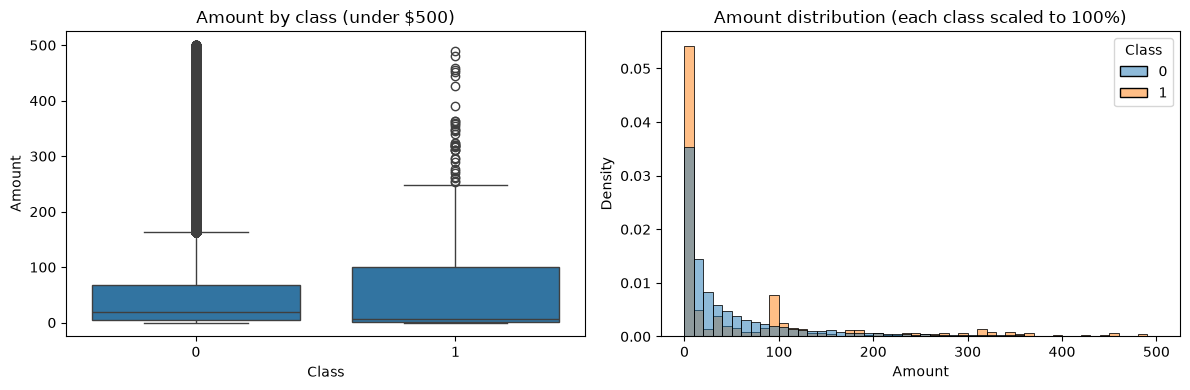

In [21]:
print(df.groupby("Class")["Amount"].describe().round(2))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x="Class", y="Amount", data=df[df.Amount < 500], ax=ax[0])
ax[0].set_title("Amount by class (under $500)")
sns.histplot(data=df[df.Amount < 500], x="Amount", hue="Class", bins=50, stat="density",
             common_norm=False, ax=ax[1])
ax[1].set_title("Amount distribution (each class scaled to 100%)")
plt.tight_layout(); plt.show()

**Finding:** fraud has a slightly higher *average* amount, but the **median** fraud amount is far
*lower* than the median legitimate amount (many small "test" transactions). Amount alone is
not a reliable fraud signal.

      total_txns  fraud_txns  fraud_rate_pct
hour                                        
2.0         3308          48           1.451
4.0         2204          23           1.044
3.0         3487          17           0.488
5.0         2988          11           0.368
7.0         7233          23           0.318
11.0       16781          53           0.316


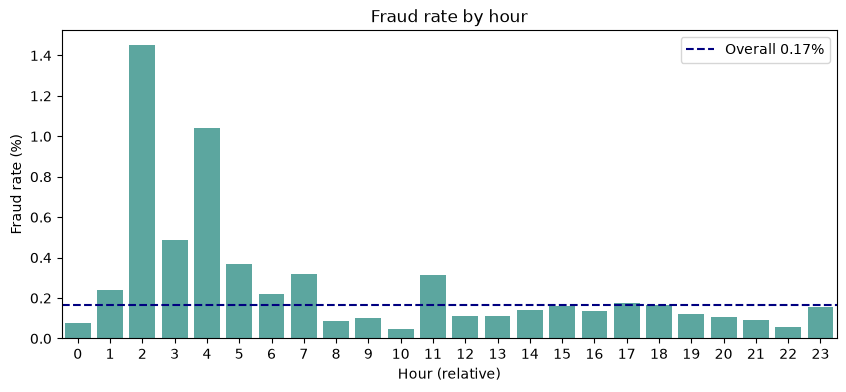

In [22]:
df["hour"] = (df["Time"] // 3600) % 24
hourly = df.groupby("hour")["Class"].agg(total_txns="count", fraud_txns="sum")
hourly["fraud_rate_pct"] = hourly["fraud_txns"] / hourly["total_txns"] * 100
overall = df["Class"].mean() * 100
print(hourly.sort_values("fraud_rate_pct", ascending=False).head(6).round(3))

plt.figure(figsize=(10, 4))
sns.barplot(x=hourly.index.astype(int), y=hourly["fraud_rate_pct"], color="#4fb3a9")
plt.axhline(overall, color="navy", ls="--", label=f"Overall {overall:.2f}%")
plt.title("Fraud rate by hour"); plt.xlabel("Hour (relative)"); plt.ylabel("Fraud rate (%)")
plt.legend(); plt.show()

**Finding:** fraud is concentrated in hours **2-4**, where the fraud rate is several times the
overall rate. Those hours also have *low* transaction volume, so this is a cheap risk signal.
We turn it into a simple feature `is_night` (hours 1-5) in Section 4.

## 3. SQL analysis (SQLite)

We load the data into a SQLite database and run the queries stored in `sql/fraud_analysis.sql`.
You can also open `data/fraud.db` in VS Code and run them yourself.

In [23]:
con = sqlite3.connect("../data/fraud.db")
sql_table = raw.copy()
sql_table["hour"] = (sql_table["Time"] // 3600) % 24     # raw data (with duplicates) so Q7 can find them
sql_table.to_sql("transactions", con, if_exists="replace", index=False)

# split the .sql file into queries using the "-- Q<number>" markers
sql_text = open("../sql/fraud_analysis.sql").read()
queries = {m.group(1): m.group(2).strip()
           for m in re.finditer(r"-- (Q\d+):[^\n]*\n(.*?)(?=\n-- Q\d+:|\Z)", sql_text, re.S)}
print("Queries found:", list(queries))

def run(q):
    return pd.read_sql_query(queries[q], con)

run("Q1")

Queries found: ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10']


,total_transactions,fraud_transactions,fraud_rate_pct
0,284807,492,0.1727


In [24]:
run("Q2").head(5)

,hour,total_txns,fraud_txns,fraud_rate_pct
0,2.0,3328,57,1.7127
1,4.0,2209,23,1.0412
2,3.0,3492,17,0.4868
3,5.0,2990,11,0.3679
4,7.0,7243,23,0.3175


In [25]:
run("Q6")

,period,total_txns,fraud_txns,fraud_rate_pct
0,Night (1-5 AM),16239,118,0.7266
1,Rest of day,268568,374,0.1393


In [26]:
run("Q7")

,total_rows,unique_rows,duplicate_rows_to_remove
0,284807,283726,1081


**Why Q7 matters:** SQL's `GROUP BY` on *all* columns finds the same **1,081** duplicate rows as pandas.
(The old project used only 3 columns for this check and got a different number - always define
"duplicate" carefully.)

Queries Q9 and Q10 use a window function and the model output; they run after Section 6.

## 4. Features, train/test split and model

**Features:** `V1`-`V28`, `Amount`, and `is_night` (from the EDA). We do **not** use `Time` as a
feature (seconds since the file started has no meaning for a new transaction).

**Split first, scale second:** the scaler is part of a `Pipeline`, so it only learns from
training data (scaling before the split leaks information from the test set).

**Model:** Logistic Regression with `class_weight="balanced"` - simple, explainable, gives probabilities.

In [27]:
df["is_night"] = df["hour"].between(1, 5).astype(int)
FEATURES = [f"V{i}" for i in range(1, 29)] + ["Amount", "is_night"]

X, y = df[FEATURES], df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| fraud in test:", y_test.sum())

model = make_pipeline(StandardScaler(),
                      LogisticRegression(max_iter=1000, class_weight="balanced"))
model.fit(X_train, y_train)

test_proba = model.predict_proba(X_test)[:, 1]

Train: (226980, 30) | Test: (56746, 30) | fraud in test: 95


## 5. Model evaluation and choosing the threshold

A model outputs a **probability**. A *threshold* turns it into a decision ("flag if probability >= t").
The default 0.5 is arbitrary, so we first see how the model does at 0.5, then pick a better threshold.

              precision    recall  f1-score   support

       Legit      1.000     0.975     0.987     56651
       Fraud      0.056     0.874     0.105        95

    accuracy                          0.975     56746
   macro avg      0.528     0.924     0.546     56746
weighted avg      0.998     0.975     0.986     56746

ROC-AUC: 0.965   PR-AUC: 0.668
Accuracy at 0.5: 0.9751  (a 'predict all legit' model would score 0.9983)


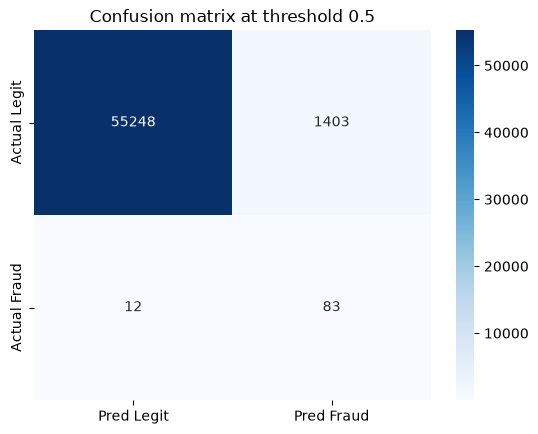

In [28]:
pred_05 = (test_proba >= 0.5).astype(int)
print(classification_report(y_test, pred_05, digits=3, target_names=["Legit", "Fraud"]))

from sklearn.metrics import recall_score, precision_score
recall_05 = recall_score(y_test, pred_05)
prec_05 = precision_score(y_test, pred_05)
roc_auc = roc_auc_score(y_test, test_proba)
pr_auc  = average_precision_score(y_test, test_proba)
print(f"ROC-AUC: {roc_auc:.3f}   PR-AUC: {pr_auc:.3f}")
print(f"Accuracy at 0.5: {accuracy_score(y_test, pred_05):.4f}  "
      f"(a 'predict all legit' model would score {1 - y_test.mean():.4f})")

cm = confusion_matrix(y_test, pred_05)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Legit", "Pred Fraud"], yticklabels=["Actual Legit", "Actual Fraud"])
plt.title("Confusion matrix at threshold 0.5"); plt.show()

**Reading this:** at 0.5 the model catches about 87% of fraud (**recall**) but only ~5-6% of its alerts are
real fraud (**precision**) - roughly 1,500 alerts for 95 frauds. ROC-AUC looks great (0.96+) but
**PR-AUC (~0.67) is the honest number** for such rare fraud.

Accuracy (97.5%) is *lower* than the "predict all legit" baseline (99.83%) yet the model is far more
useful - that is exactly why accuracy is the wrong metric here.

### Picking a threshold with a simple cost rule

Assumptions (state these in an interview - they are **assumptions, not real bank numbers**):
- a **missed fraud** costs the transaction amount;
- every **flagged** transaction costs `REVIEW_COST` ($5) to review or to annoy the customer.

We choose the threshold on the **training data only** (using cross-validated predictions) so the test set
stays untouched for the final result.

Cost-optimal threshold (High tier): 0.99


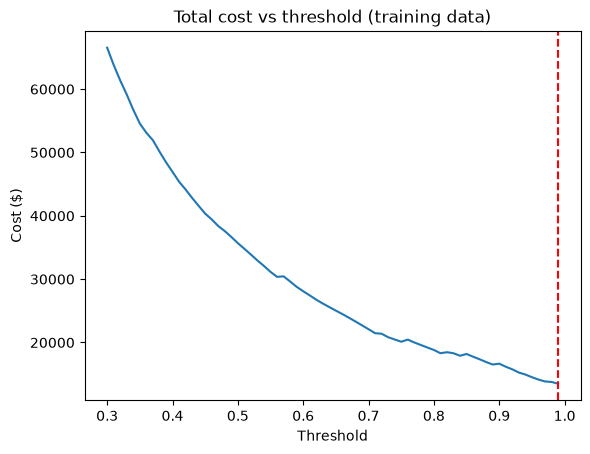

In [29]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_proba = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
train_amount = X_train["Amount"].values
train_fraud = y_train.values == 1

def total_cost(proba, amount, is_fraud, t):
    flagged = proba >= t
    missed_loss = amount[is_fraud & ~flagged].sum()
    return missed_loss + REVIEW_COST * flagged.sum()

grid = np.round(np.arange(0.30, 1.0, 0.01), 2)
costs = [total_cost(train_proba, train_amount, train_fraud, t) for t in grid]
HIGH_T = float(grid[int(np.argmin(costs))])       # cost-optimal threshold -> "High" tier
MED_T = 0.50                                       # default threshold -> "Medium" tier starts here
print(f"Cost-optimal threshold (High tier): {HIGH_T}")

plt.plot(grid, costs); plt.axvline(HIGH_T, color="red", ls="--")
plt.title("Total cost vs threshold (training data)"); plt.xlabel("Threshold"); plt.ylabel("Cost ($)")
plt.show()

In [30]:
# What each threshold does on the TEST set
test_amount = X_test["Amount"].values
test_fraud = y_test.values == 1
rows = []
for t in [0.5, 0.7, 0.9, HIGH_T]:
    f = test_proba >= t
    rows.append({"threshold": t, "alerts": int(f.sum()), "fraud_caught": int((f & test_fraud).sum()),
                 "recall_%": round(100 * (f & test_fraud).sum() / test_fraud.sum(), 1),
                 "precision_%": round(100 * (f & test_fraud).sum() / max(f.sum(), 1), 1),
                 "total_cost_$": round(total_cost(test_proba, test_amount, test_fraud, t))})
pd.DataFrame(rows)

,threshold,alerts,fraud_caught,recall_%,precision_%,total_cost_$
0,0.50,1486,83,87.4,5.6,10029
1,0.70,726,82,86.3,11.3,6232
2,0.90,284,77,81.1,27.1,4478
3,0.99,115,75,78.9,65.2,4364


## 6. Risk score and risk tiers

- **Risk score** = fraud probability x 100 (0-100). *Note:* because of `class_weight="balanced"` the
  probabilities are **inflated** (not real-world chances) - use the score to **rank** transactions.
- **High** (score >= cost-optimal threshold): investigate / block.
- **Medium** (50 to High): extra verification, e.g. OTP.
- **Low** (below 50): approve.

In [31]:
scored = pd.DataFrame({
    "TransactionID": X_test.index,
    "TransactionAmount": X_test["Amount"].values,
    "Hour": X_test.index.map(df["hour"]).astype(int),
    "FraudProbability": test_proba,
    "RiskScore": np.round(test_proba * 100, 1),
    "ActualOutcome": np.where(test_fraud, "Fraud", "Legitimate"),
})
scored["RiskLevel"] = np.select(
    [test_proba >= HIGH_T, test_proba >= MED_T], ["High", "Medium"], default="Low")
scored = scored[["TransactionID", "TransactionAmount", "Hour", "FraudProbability",
                 "RiskScore", "RiskLevel", "ActualOutcome"]]
scored.to_csv("../data/risk_scored_transactions.csv", index=False)
scored.to_sql("scored_transactions", con, if_exists="replace", index=False)

tier = scored.groupby("RiskLevel").agg(
    txns=("RiskLevel", "size"),
    fraud_txns=("ActualOutcome", lambda s: (s == "Fraud").sum()),
    total_value=("TransactionAmount", "sum")).reindex(["High", "Medium", "Low"])
tier["fraud_value"] = scored[scored.ActualOutcome == "Fraud"].groupby("RiskLevel")["TransactionAmount"].sum()
tier = tier.fillna(0).round(0)
tier

,txns,fraud_txns,total_value,fraud_value
RiskLevel,,,,
High,115,75,109708.0,10977.0
Medium,1371,8,308796.0,1191.0
Low,55260,12,4621388.0,2599.0


In [32]:
# SQL on the model output (Q9 window function, Q10 tier summary)
display(run("Q9"))
run("Q10")

,hour,fraud_txns,cumulative_fraud,cumulative_pct_of_fraud
0,0.0,6,6,1.2
1,1.0,10,16,3.3
2,2.0,57,73,14.8
3,3.0,17,90,18.3
4,4.0,23,113,23.0
5,5.0,11,124,25.2
6,6.0,9,133,27.0
7,7.0,23,156,31.7
8,8.0,9,165,33.5
9,9.0,16,181,36.8


,RiskLevel,txns,fraud_txns,fraud_pct_of_tier,total_value,fraud_value
0,High,115,75,65.22,109708.0,10977.0
1,Medium,1371,8,0.58,308796.0,1191.0
2,Low,55260,12,0.02,4621388.0,2599.0


In [33]:
high = scored[scored.RiskLevel == "High"]
high_fraud = high[high.ActualOutcome == "Fraud"]
total_fraud_value = scored.loc[scored.ActualOutcome == "Fraud", "TransactionAmount"].sum()

print(f"High-risk alerts:            {len(high):,}")
print(f"Fraud caught in High tier:   {len(high_fraud)} of {test_fraud.sum()}")
print(f"Fraud $ caught (High tier):  ${high_fraud.TransactionAmount.sum():,.0f} of ${total_fraud_value:,.0f} total fraud $ in test set")
print(f"Value of all High-tier txns: ${high.TransactionAmount.sum():,.0f}")
print(f"Precision of High tier:      {100 * len(high_fraud) / len(high):.1f}%")

High-risk alerts:            115
Fraud caught in High tier:   75 of 95
Fraud $ caught (High tier):  $10,977 of $14,766 total fraud $ in test set
Value of all High-tier txns: $109,708
Precision of High tier:      65.2%


**Business reading:** the High tier is a short, high-precision work-list for investigators, while the Medium
tier gets a light-touch check and Low is approved automatically. Tune the thresholds to the
real cost of fraud vs customer friction and the size of the investigation team.

## 7. Dashboard images and results file

These two PNGs are built with matplotlib (not Power BI). `POWERBI_GUIDE.md` shows how to rebuild the same
pages in Power BI Desktop from `data/risk_scored_transactions.csv`.

In [34]:
colors = {"High": "#c0392b", "Medium": "#e6ae48", "Low": "#4fd1c5"}
navy = "#1f3864"
high_t_pred = test_proba >= HIGH_T
cm_high = confusion_matrix(test_fraud, high_t_pred)

# ---- Page 1: model overview
fig = plt.figure(figsize=(16, 9)); fig.suptitle("Fraud Risk Analytics - Executive Summary", fontsize=20, color=navy, x=0.02, ha="left")
gs = fig.add_gridspec(2, 3, hspace=0.45, wspace=0.3)
ax = fig.add_subplot(gs[0, 0])
ax.bar(hourly.index.astype(int), hourly["fraud_rate_pct"], color=["#e6ae48" if h in (2, 4) else "#4fd1c5" for h in hourly.index])
ax.axhline(overall, color=navy, ls="--", lw=1); ax.set_title("Fraud rate by hour (%)"); ax.set_xlabel("Hour (relative)")
ax = fig.add_subplot(gs[0, 1])
fpr, tpr, _ = roc_curve(y_test, test_proba); ax.plot(fpr, tpr, color=navy); ax.plot([0, 1], [0, 1], "--", color="grey")
ax.set_title(f"ROC curve (AUC {roc_auc:.3f})"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax = fig.add_subplot(gs[0, 2])
p, r, _ = precision_recall_curve(y_test, test_proba); ax.plot(r, p, color="#e6ae48")
ax.set_title(f"Precision-Recall curve (PR-AUC {pr_auc:.3f})"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax = fig.add_subplot(gs[1, 0])
sns.heatmap(cm_high, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Pred Legit", "Pred High"], yticklabels=["Legit", "Fraud"])
ax.set_title(f"Confusion matrix (High tier, threshold {HIGH_T})")
ax = fig.add_subplot(gs[1, 1])
amt = df.groupby("Class")["Amount"].agg(["mean", "median"]).rename(index={0: "Legit", 1: "Fraud"})
amt.plot.bar(ax=ax, color=["#4fd1c5", "#e6ae48"], rot=0); ax.set_title("Amount: mean vs median ($)")
ax = fig.add_subplot(gs[1, 2]); ax.axis("off")
txt = (f"Key facts\n\n- {len(df):,} transactions after cleaning\n- Fraud rate {overall:.2f}%\n"
       f"- ROC-AUC {roc_auc:.3f}, PR-AUC {pr_auc:.3f}\n- At 0.5: recall {recall_05:.0%}, precision {prec_05:.1%}\n"
       f"- High tier: {len(high_fraud)}/{test_fraud.sum()} fraud caught\n- Cost rule: missed fraud = amount,\n  review = ${REVIEW_COST}/alert (assumed)")
ax.text(0, 1, txt, va="top", fontsize=13, color=navy)
fig.savefig("../dashboards/fraud_risk_dashboard_summary.png", dpi=110, bbox_inches="tight"); plt.close(fig)

# ---- Page 2: risk monitoring
fig, axes = plt.subplots(1, 3, figsize=(16, 5)); fig.suptitle("Fraud Risk Analytics - Risk Monitoring (test set)", fontsize=18, color=navy, x=0.01, ha="left")
order = ["Low", "Medium", "High"]
cnt = scored["RiskLevel"].value_counts().reindex(order)
axes[0].bar(order, cnt.values, color=[colors[o] for o in order]); axes[0].set_title("Transactions per risk tier")
for i, v in enumerate(cnt.values): axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")
fr = tier["fraud_txns"].reindex(order)
axes[1].bar(order, fr.values, color=[colors[o] for o in order]); axes[1].set_title("Actual fraud cases per tier")
for i, v in enumerate(fr.values): axes[1].text(i, v, f"{int(v)}", ha="center", va="bottom")
axes[2].barh(["All fraud $\n(test set)", "Fraud $ caught\n(High tier)", "Value flagged\n(High tier)"],
             [total_fraud_value, high_fraud.TransactionAmount.sum(), high.TransactionAmount.sum()], color=[navy, "#c0392b", "#e6ae48"])
axes[2].set_title("Dollar view ($)")
for i, v in enumerate([total_fraud_value, high_fraud.TransactionAmount.sum(), high.TransactionAmount.sum()]): axes[2].text(v, i, f" ${v:,.0f}", va="center")
axes[2].set_xlim(0, high.TransactionAmount.sum() * 1.3)
plt.tight_layout(); fig.savefig("../dashboards/fraud_risk_dashboard_page2.png", dpi=110, bbox_inches="tight"); plt.close(fig)

results = {
    "rows_after_cleaning": int(len(df)), "duplicates_removed": int(len(raw) - len(df)),
    "fraud_rate_pct": round(overall, 4), "roc_auc": round(roc_auc, 3), "pr_auc": round(pr_auc, 3),
    "recall_at_0.5": round(float(recall_05), 3), "precision_at_0.5": round(float(prec_05), 3),
    "alerts_at_0.5": int(pred_05.sum()), "high_threshold": HIGH_T, "review_cost_assumed": REVIEW_COST,
    "high_alerts": int(len(high)), "high_fraud_caught": int(len(high_fraud)), "test_fraud_total": int(test_fraud.sum()),
    "high_precision_pct": round(100 * len(high_fraud) / len(high), 1),
    "high_value_flagged": round(float(high.TransactionAmount.sum())),
    "fraud_value_caught_high": round(float(high_fraud.TransactionAmount.sum())),
    "fraud_value_total_test": round(float(total_fraud_value)),
    "medium_alerts": int((scored.RiskLevel == "Medium").sum()),
    "medium_fraud": int(tier.loc["Medium", "fraud_txns"]),
}
json.dump(results, open("../data/results.json", "w"), indent=2)
con.close()
print(json.dumps(results, indent=2))

{
  "rows_after_cleaning": 283726,
  "duplicates_removed": 1081,
  "fraud_rate_pct": 0.1667,
  "roc_auc": 0.965,
  "pr_auc": 0.668,
  "recall_at_0.5": 0.874,
  "precision_at_0.5": 0.056,
  "alerts_at_0.5": 1486,
  "high_threshold": 0.99,
  "review_cost_assumed": 5,
  "high_alerts": 115,
  "high_fraud_caught": 75,
  "test_fraud_total": 95,
  "high_precision_pct": 65.2,
  "high_value_flagged": 109708,
  "fraud_value_caught_high": 10977,
  "fraud_value_total_test": 14766,
  "medium_alerts": 1371,
  "medium_fraud": 8
}


## 8. Key findings and limitations

1. Fraud is rare (0.17%) - **accuracy is misleading**; use recall, precision and PR-AUC.
2. Fraud clusters in relative hours **2-4**: a cheap, explainable risk signal (`is_night`).
3. Fraud **average** amount is higher but the **median** is lower - amount alone does not detect fraud.
4. At the default 0.5 threshold the model has high recall but very low precision (many false alerts).
   A **cost-based threshold** + **risk tiers** give a much more usable alert volume.
5. 1,081 duplicate rows were removed before modelling (checked in both pandas and SQL).

**Limitations (say these honestly):** 2 days of 2013 data; anonymised features; no merchant / geo /
customer history; cost numbers are assumptions; probabilities are not calibrated; one model, one split;
results on 95 test frauds can move a lot with a different random split.

**Next steps:** XGBoost / LightGBM, cross-validated PR-AUC, probability calibration, SHAP explanations.